# Activity 3 — Multi-Layer Perceptrons

**Author:** Eduardo Takei Yaginuma  
**Reproducibility:** dataset generation and splits use seed 42; the paired depth comparison uses seeds 7, 42, and 2026.  
**AI disclosure:** OpenAI Codex assisted with scaffolding, numerical verification, figures, and prose revision. The author reviewed every result and can explain the implementation.

This notebook follows the statement in order. The MLP uses NumPy only; scikit-learn is restricted to the permitted generators, splits, baselines, and confusion matrix.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
from IPython.display import Image, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'mkdocs.yml').exists())
CODE = ROOT / 'docs' / 'exercises' / 'mlp' / 'code'
sys.path.insert(0, str(CODE))
rng = np.random.default_rng(42)
print('Repository root:', ROOT)
print('Main generator:', rng)

Repository root: /Users/eduardoyaginuma/Documents/Repositorios/insper/neural-networks
Main generator: Generator(PCG64)


## Exercise 1 — One step of backpropagation, by hand

### A — Forward pass

For $\mathbf{x}=[0.5,-0.2]^T$:

$$z_1^{(1)}=0.3(0.5)+(-0.1)(-0.2)+0.1=\mathbf{0.2700},$$
$$z_2^{(1)}=0.2(0.5)+0.4(-0.2)-0.2=\mathbf{-0.1800}.$$

Thus $\mathbf h^{(1)}=\tanh(\mathbf z^{(1)})=\mathbf{[0.2636,-0.1781]}$. The output is

$$u^{(2)}=0.5(0.2636248)-0.3(-0.1780809)+0.2=\mathbf{0.3852},$$
$$\hat y=\tanh(u^{(2)})=\mathbf{0.3672},\qquad L=(1-\hat y)^2=\mathbf{0.4004}.$$

### B — Backward pass

Starting at the loss,

$$\frac{\partial L}{\partial\hat y}=2(\hat y-y)=\mathbf{-1.2655},$$
$$\delta^{(2)}=\frac{\partial L}{\partial u^{(2)}}=-1.2655069(1-0.3672466^2)=\mathbf{-1.0948}.$$

Therefore

$$\frac{\partial L}{\partial\mathbf W^{(2)}}=\delta^{(2)}\mathbf h^{(1)}=\mathbf{[-0.2886,0.1950]},\qquad \frac{\partial L}{\partial b^{(2)}}=\mathbf{-1.0948}.$$

Backpropagating,

$$\frac{\partial L}{\partial\mathbf h^{(1)}}=\delta^{(2)}\mathbf W^{(2)}=\mathbf{[-0.5474,0.3284]},$$
$$\boldsymbol\delta^{(1)}=\frac{\partial L}{\partial\mathbf z^{(1)}}=\frac{\partial L}{\partial\mathbf h^{(1)}}\odot(1-(\mathbf h^{(1)})^2)=\mathbf{[-0.5094,0.3180]}.$$

The hidden-layer gradients are

$$\frac{\partial L}{\partial\mathbf W^{(1)}}=\boldsymbol\delta^{(1)}\mathbf x^T=\mathbf{\begin{bmatrix}-0.2547&0.1019\\0.1590&-0.0636\end{bmatrix}},\qquad \frac{\partial L}{\partial\mathbf b^{(1)}}=\mathbf{[-0.5094,0.3180]}.$$

### C — Parameter update

With $\eta=0.3$, all supplied parameters become

$$\mathbf W^{(1)}_{new}=\mathbf{\begin{bmatrix}0.3764&-0.1306\\0.1523&0.4191\end{bmatrix}},\quad \mathbf b^{(1)}_{new}=\mathbf{[0.2528,-0.2954]},$$
$$\mathbf W^{(2)}_{new}=\mathbf{[0.5866,-0.3585]},\quad b^{(2)}_{new}=\mathbf{0.5284}.$$

The prompt says “eight parameters,” but the given shapes contain $4+2+2+1=9$ scalar parameters; all nine are shown. A second pass gives $\hat y=0.7112$ and $L=0.0834$, so loss falls from 0.4004 because the finite update moves safely along the negative gradient.

In [2]:
# Independent numerical check of every Exercise 1 value.
x = np.array([0.5, -0.2]); y = 1.0
W1 = np.array([[0.3, -0.1], [0.2, 0.4]]); b1 = np.array([0.1, -0.2])
W2 = np.array([0.5, -0.3]); b2 = 0.2; eta = 0.3
z1 = W1 @ x + b1; h1 = np.tanh(z1); u2 = W2 @ h1 + b2; yhat = np.tanh(u2)
loss = (y - yhat)**2; dL_dyhat = 2 * (yhat - y); delta2 = dL_dyhat * (1-yhat**2)
dW2 = delta2*h1; db2 = delta2; dL_dh1 = delta2*W2
delta1 = dL_dh1*(1-h1**2); dW1 = np.outer(delta1, x); db1_grad = delta1
W1n, b1n = W1-eta*dW1, b1-eta*db1_grad
W2n, b2n = W2-eta*dW2, b2-eta*db2
second_yhat = np.tanh(W2n @ np.tanh(W1n @ x + b1n) + b2n)
print('z1 =', z1, ' h1 =', h1)
print('u2 =', u2, ' yhat =', yhat, ' L =', loss)
print('dL/dyhat =', dL_dyhat, ' delta2 =', delta2)
print('dW2 =', dW2, ' db2 =', db2)
print('dL/dh1 =', dL_dh1, ' delta1 =', delta1)
print('dW1 =\n', dW1, ' db1 =', db1_grad)
print('updated W1 =\n', W1n, ' updated b1 =', b1n)
print('updated W2 =', W2n, ' updated b2 =', b2n)
print('second yhat =', second_yhat, ' second L =', (y-second_yhat)**2)

z1 = [ 0.27 -0.18]  h1 = [ 0.26362484 -0.17808087]
u2 = 0.38523667817130075  yhat = 0.36724656264510797  L = 0.4003769124844312
dL/dyhat = -1.265506874709784  delta2 = -1.0948279147135995
dW2 = [-0.28862383  0.19496791]  db2 = -1.0948279147135995
dL/dh1 = [-0.54741396  0.32844837]  delta1 = [-0.50936975  0.31803236]
dW1 =
 [[-0.25468488  0.10187395]
 [ 0.15901618 -0.06360647]]  db1 = [-0.50936975  0.31803236]
updated W1 =
 [[ 0.37640546 -0.13056219]
 [ 0.15229515  0.41908194]]  updated b1 = [ 0.25281093 -0.29540971]
updated W2 = [ 0.58658715 -0.35849037]  updated b2 = 0.5284483744140799
second yhat = 0.7111805295491177  second L = 0.08341668651152807


## Exercises 2–4 — Shared MLP implementation

The next cell loads and displays the complete model source used by every experiment. The class accepts arbitrary layer sizes. Its `forward`, `backward`, `update`, and `fit` methods are reused untouched for binary, multi-class, shallow, and deep networks. There is no autodiff or neural-network library.

In [3]:
# Execute the exact source used by the report and print it for auditability.
mlp_source = (CODE / 'mlp.py').read_text()
exec(compile(mlp_source, str(CODE / 'mlp.py'), 'exec'), globals())
print(mlp_source)

"""A small, fully NumPy multi-layer perceptron.

The same implementation handles binary and multi-class classification.  There
is no autograd: ``backward`` contains the complete chain rule, and ``update``
performs gradient descent explicitly.
"""
from __future__ import annotations

import numpy as np


class MLP:
    """Dense tanh network with sigmoid or softmax output."""

    def __init__(self, layer_sizes, task, rng):
        if len(layer_sizes) < 3:
            raise ValueError("layer_sizes must include input, hidden and output")
        if task not in {"binary", "multiclass"}:
            raise ValueError("task must be 'binary' or 'multiclass'")
        if task == "binary" and layer_sizes[-1] != 1:
            raise ValueError("binary classification requires one output unit")

        self.layer_sizes = tuple(layer_sizes)
        self.task = task
        self.weights = []
        self.biases = []
        for fan_in, fan_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            # 

## Exercise 2 — Binary classification a straight line cannot do

### A — Generate the data

The specified generator creates one central class-0 cluster and two opposing class-1 clusters. The split is 80/20, stratified, at seed 42.

### B — Establish the baseline

Logistic regression obtains **47.50%** (95/200). A single half-plane cannot contain both opposing outer clusters while excluding the central cluster.

### C — Implement and train

Architecture **2–8–1**, hidden `tanh`, sigmoid output, binary cross-entropy, learning rate **0.1**, and **2,000** full-batch epochs produce **92.00%** test accuracy and final training loss **0.113632**.

### D — Analysis

Figure 3 shows two class-1 lobes around the diagonal extremes and a class-0 band around the origin. Eight hidden units combine several cuts into this non-convex, effectively disconnected rule. Logistic regression has only one cut, explaining the measured 47.50% versus 92.00%.

## Exercise 3 — Multi-class, same network

### A — Generate the data

The exact requested generator creates 1,500 samples, 4 informative features, 3 classes, and 2 clusters per class. The stratified 80/20 split uses seed 42; scaling is fitted on training data only.

### B — Softmax plus cross-entropy

For $p_j=e^{u_j}/\sum_r e^{u_r}$, $L=-\sum_jy_j\log p_j$, and $\partial p_j/\partial u_k=p_j(\mathbb 1[j=k]-p_k)$:

$$\frac{\partial L}{\partial u_k}=-\sum_jy_j(\mathbb 1[j=k]-p_k)=-y_k+p_k\sum_jy_j=\boxed{p_k-y_k}.$$

The batch code therefore starts backpropagation with $(\mathbf P-\mathbf Y)/N$.

### C — Train and evaluate

Architecture **4–12–3**, learning rate **0.1**, and **3,000** epochs give **84.00%** test accuracy and loss **0.350290** at seed 42.

### D — Analysis

The confusion matrix is $[[85,6,9],[14,76,10],[4,5,91]]$. Classes **0 and 1** are most confused: $6+14=20$ bidirectional errors. Six clusters spread across four dimensions create overlapping, non-convex class regions. The hidden layer models these better than the 66.33% multinomial-logistic baseline.

## Exercise 4 — Does a second hidden layer help?

### A — Deeper network

The **4–12–12–3** model changes only depth. At seed 42, under the same learning rate and 3,000-epoch budget, it reaches **87.33%** with loss **0.274437**.

### B — Three-seed comparison

Seeds 7, 42, and 2026 give shallow accuracies 84.67%, 84.00%, 84.67% and deep accuracies 85.00%, 87.33%, 86.67%. Their means are **84.44%** and **86.33%**: deep minus shallow is **+1.89 percentage points**.

| Model | Hidden layers | Parameters | Mean final train loss | Mean test accuracy |
|---|---:|---:|---:|---:|
| Exercise 3 | 1 | 99 | 0.340027 | 84.44% |
| Exercise 4 | 2 | 255 | 0.272390 | 86.33% |

### C — Analysis

Depth helps modestly in these runs, and the lower deep training loss agrees with test accuracy. Yet six clusters are simple enough that one hidden layer already works; 156 extra parameters buy only 1.89 points and add optimization and variance costs. Hierarchical data such as images, where edges compose into textures, parts, and objects, should reward depth more reliably.

In [4]:
# Run the canonical entry point in a clean process. This is the same command
# used from the terminal, so notebook and CLI artifacts are byte-identical.
import subprocess
project_python = ROOT / 'env' / 'bin' / 'python'
runner = str(project_python) if project_python.exists() else sys.executable
completed = subprocess.run(
    [runner, str(CODE / 'run_report.py')], cwd=ROOT,
    check=True, capture_output=True, text=True)
print(completed.stdout)
results = json.loads((ROOT / 'results' / 'mlp' / 'results.json').read_text())

  figure -> docs/exercises/mlp/figures/fig1_binary_data.png
  figure -> docs/exercises/mlp/figures/fig2_binary_loss.png
  figure -> docs/exercises/mlp/figures/fig3_decision_boundary.png
  figure -> docs/exercises/mlp/figures/fig4_multiclass_loss.png
  figure -> docs/exercises/mlp/figures/fig5_confusion_matrix.png
  figure -> docs/exercises/mlp/figures/fig6_depth_comparison.png
  results -> results/mlp/results.json
{
  "reproducibility": {
    "main_seed": 42,
    "comparison_seeds": [
      7,
      42,
      2026
    ],
    "preprocessing": "training-set mean and standard deviation only"
  },
  "exercise1": {
    "z1": [
      0.27,
      -0.18000000000000002
    ],
    "h1": [
      0.26362483547220333,
      -0.1780808681173302
    ],
    "u2": 0.38523667817130075,
    "yhat": 0.36724656264510797,
    "loss": 0.4003769124844312,
    "dL_dyhat": -1.265506874709784,
    "delta2": -1.0948279147135995,
    "dW2": [
      -0.28862382888674815,
      0.19496790549128415
    ],
    "db2": 

### Figures 1–3 — Binary experiment

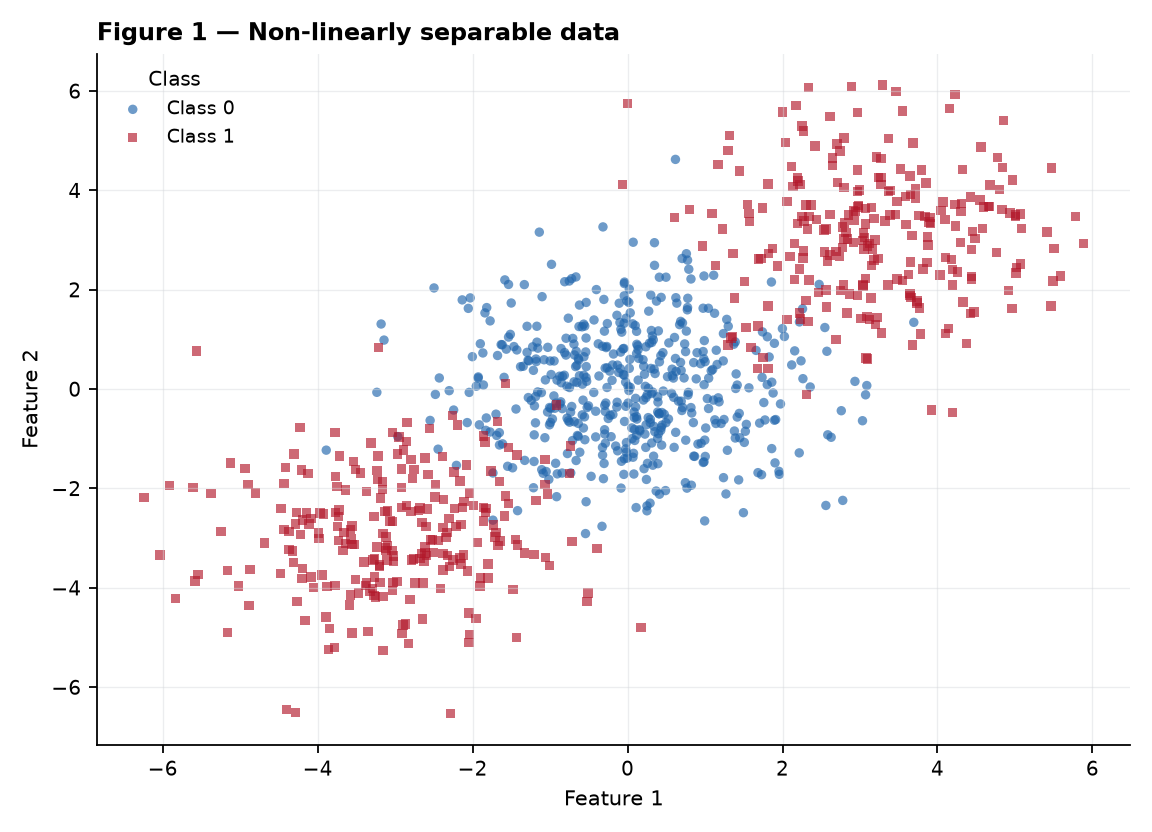

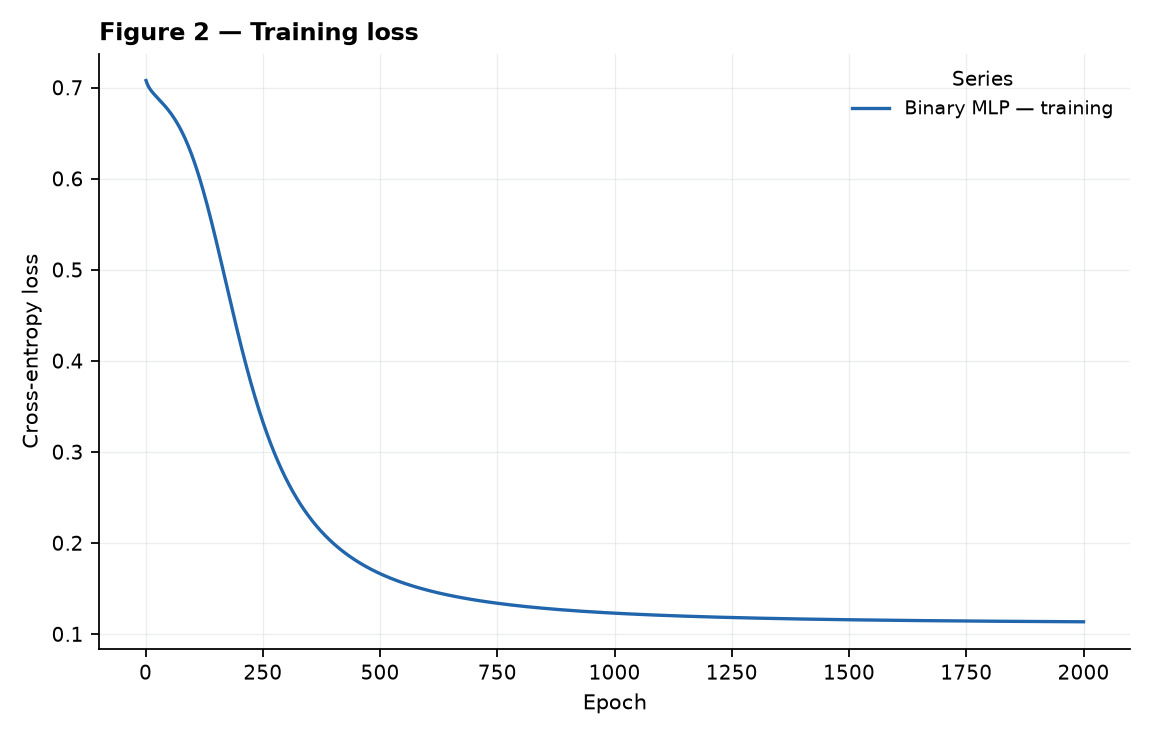

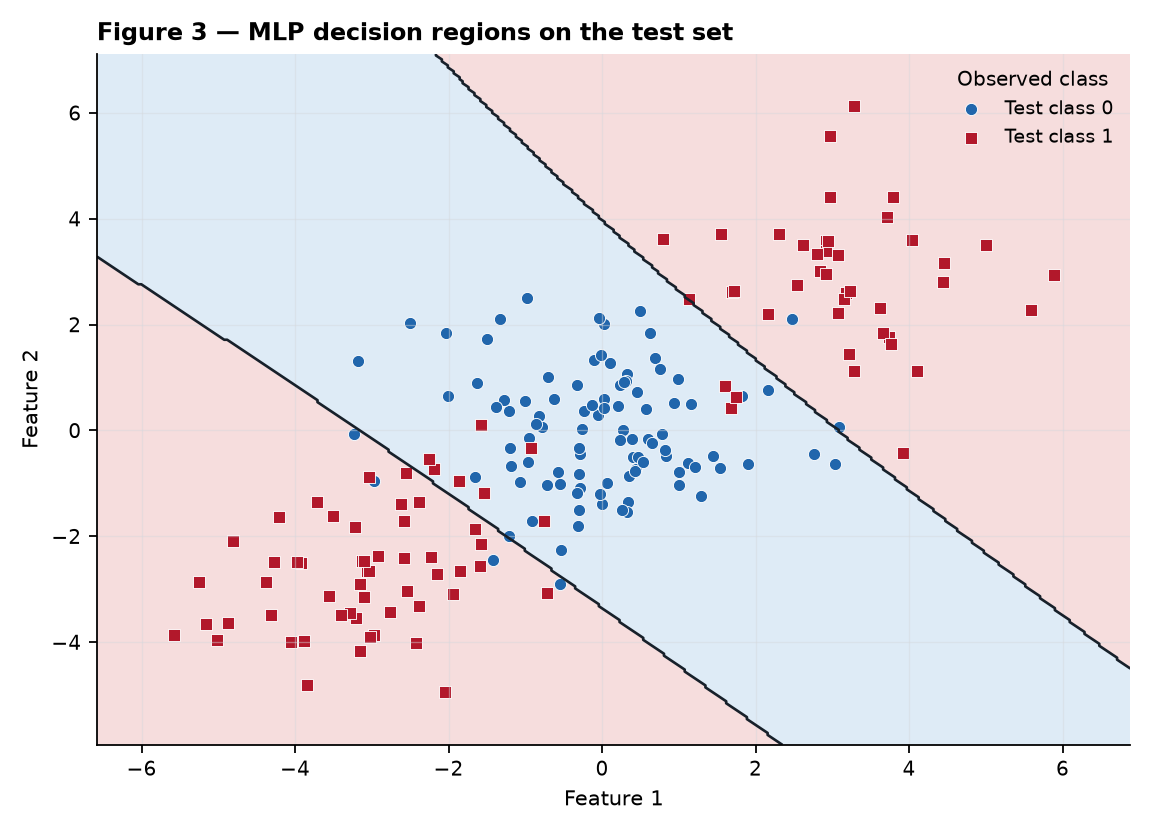

In [5]:
FIG = ROOT / 'docs' / 'exercises' / 'mlp' / 'figures'
for name in ['fig1_binary_data.png', 'fig2_binary_loss.png', 'fig3_decision_boundary.png']:
    display(Image(filename=str(FIG / name)))

### Figures 4–6 — Multi-class and depth experiments

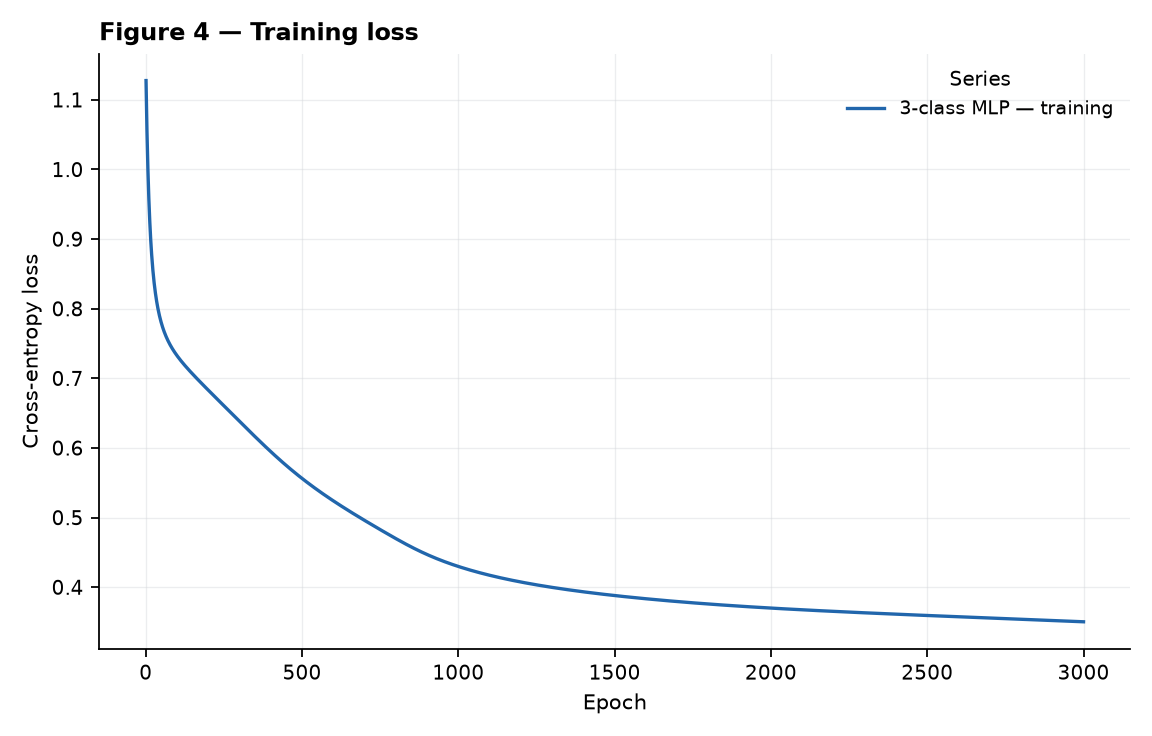

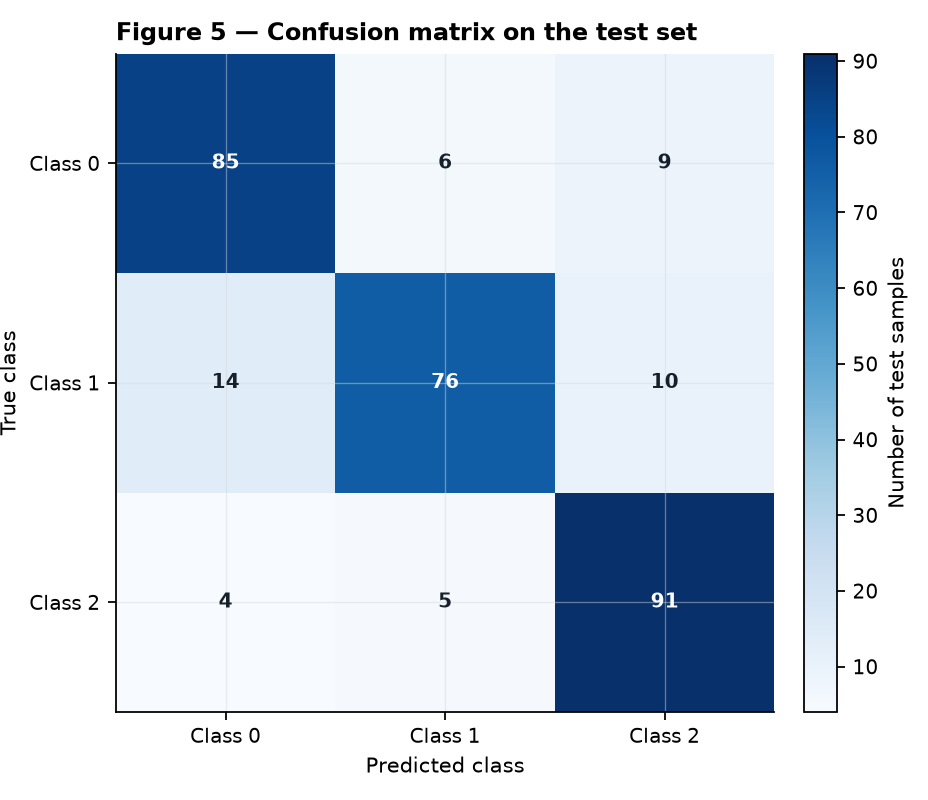

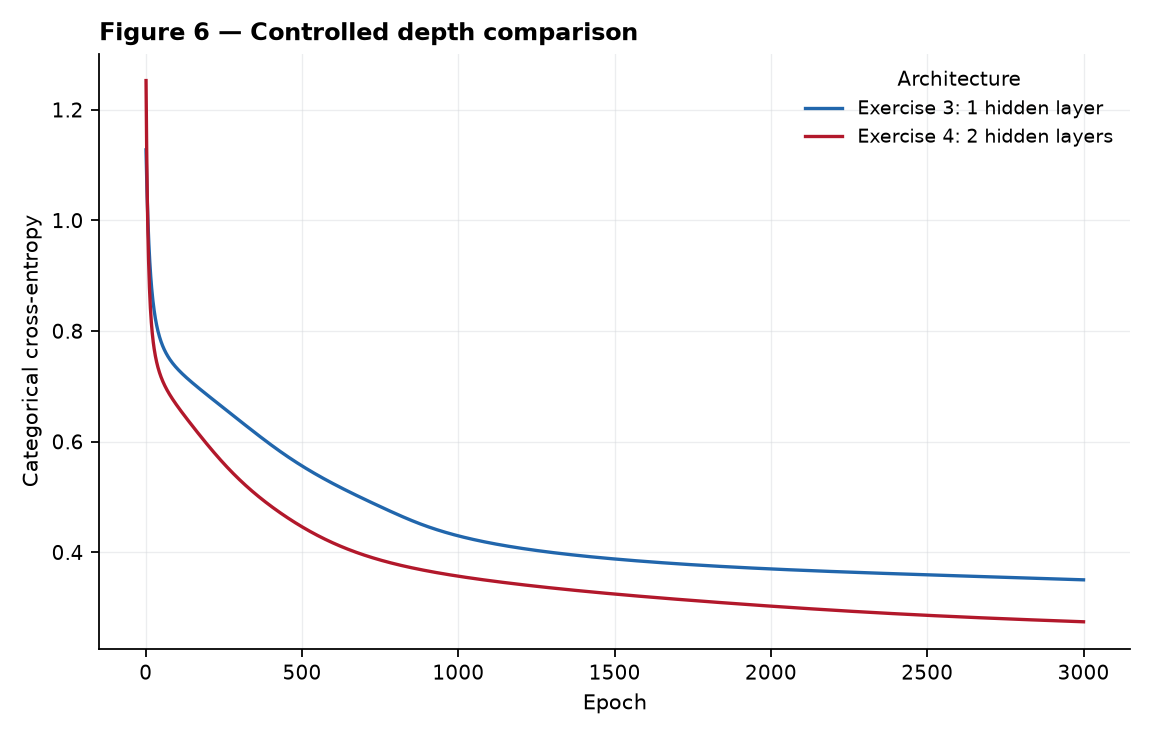

In [6]:
for name in ['fig4_multiclass_loss.png', 'fig5_confusion_matrix.png', 'fig6_depth_comparison.png']:
    display(Image(filename=str(FIG / name)))

## Results summary

| # | Quantity | Value |
|---|---|---|
| 1 | Ex. 1 — $\mathbf z^{(1)}$ and $\mathbf h^{(1)}$ | $[0.2700,-0.1800]$; $[0.2636,-0.1781]$ |
| 2 | Ex. 1 — $u^{(2)}$, $\hat y$, and $L$ | 0.3852; 0.3672; 0.4004 |
| 3 | Ex. 1 — all updated parameters | $W^1=[[0.3764,-0.1306],[0.1523,0.4191]]$; $b^1=[0.2528,-0.2954]$; $W^2=[0.5866,-0.3585]$; $b^2=0.5284$ |
| 4 | Ex. 2 — linear baseline | 47.50% |
| 5 | Ex. 2 — architecture and accuracy | 2–8–1; 92.00% |
| 6 | Ex. 3 — architecture and accuracy | 4–12–3; 84.00% |
| 7 | Ex. 3 — most-confused pair | Classes 0 and 1; 20 errors |
| 8 | Ex. 4 — architecture and accuracy | 4–12–12–3; 87.33% |
| 9 | Ex. 4 — mean difference | +1.89 percentage points over 3 seeds |